# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Бісюк Роман'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 1      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 1, файл lr6_варіант_01.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль «відтік» має два значення (пішов / не пішов), і треба оцінити ймовірність класу 1.

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: класи нерівні (відтоку менше третини), тож модель «ніхто не піде»
# має високу точність і нульову користь; AUC оцінює, чи вміє модель ставити ризикових вище за решту,
# а саме це потрібно для списку на обдзвін.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: рядків лише 1200, тож одна перевірка дає шумне число; повтори зменшують розкид,
# а стратифікація тримає однакову частку відтоку в кожній згортці.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.293

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
info = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': raw.apply(lambda s: s.dropna().iloc[0]),
})
info.index.name = 'стовпець'
display(info.sort_values('% пропусків', ascending=False))

print('рядків %d, стовпців %d' % raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print('стовпців текстового (невизначеного) типу:', (info['тип'].isin(['object', 'str'])).sum())
print('найбільше пропусків:', info['% пропусків'].idxmax(), info['% пропусків'].max(), '%')

,тип,унікальних,% пропусків,приклад
стовпець,,,,
код_причини_закриття,str,5,70.7,ПЕР-04
сума_повернення_депозиту,float64,351,70.7,121.49
середній_час_відповіді_хв,float64,264,33.8,25.7
трафік_ГБ,str,974,5.0,101.3
щомісячний_платіж,str,1129,4.0,270.14
аварій_на_ділянці_за_квартал,float64,6,3.0,0.0
стать,str,6,0.0,ч
місто,str,6,0.0,Стрий
id_клієнта,str,1200,0.0,K10000


рядків 1200, стовпців 26
частка відтоку: 0.293
стовпців текстового (невизначеного) типу: 13
найбільше пропусків: сума_повернення_депозиту 70.7 %


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
# 1) число, записане текстом: шукаємо значення, які не є «чистим» числом
pay = raw['щомісячний_платіж'].dropna().astype(str)
print('1) щомісячний_платіж — текст замість числа:', (~pay.str.fullmatch(r'[0-9.]+')).sum(), 'рядків')
print(pay[~pay.str.fullmatch(r'[0-9.]+')].head(5).tolist())

# 2) Excel перетворив число на дату (1900-01-25 = число 25)
trf = raw['трафік_ГБ'].dropna().astype(str)
print()
print('2) трафік_ГБ — дата замість числа:', trf.str.startswith('1900-').sum(), 'рядків')
print(trf[trf.str.startswith('1900-')].tolist())

# 3) пропуск не випадковий: час відповіді порожній рівно тоді, коли звернень не було
print()
print('3) середній_час_відповіді_хв: пропуск залежно від кількості звернень')
display(pd.crosstab(raw['кількість_звернень_у_підтримку'],
                    raw['середній_час_відповіді_хв'].isna().rename('пропуск')))

1) щомісячний_платіж — текст замість числа: 27 рядків
['393.67 грн', '426.37 грн', '331.12 грн', '369.93 грн', '341.36 грн']

2) трафік_ГБ — дата замість числа: 2 рядків
['1900-01-25 00:00:00', '1900-01-15 00:00:00']

3) середній_час_відповіді_хв: пропуск залежно від кількості звернень


пропуск,False,True
кількість_звернень_у_підтримку,,
0,0,405
1,416,0
2,260,0
3,88,0
4,25,0
5,3,0
6,3,0


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'пропуск означає, що клієнт жодного разу не звертався в підтримку, тому й часу відповіді немає'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN            -> np.nan
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, pd.Timestamp)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.number)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        txt = str(v).strip().replace(',', '.')
        if re.match(r'\d{4}-\d{2}-\d{2}', txt):      # дата, записана текстом
            return np.nan
        m = re.match(r'\d+(\.\d+)?', txt)            # число на початку рядка
        return float(m.group()) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c == 'дата_підключення':
            # дата -> порядковий номер дня
            X[c] = pd.to_datetime(s).map(lambda t: t.toordinal()).astype(float)
            how = 'дата -> номер дня'
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            how = 'число'
        else:
            num = to_number(s)
            if num.notna().sum() > 0.8 * s.notna().sum():
                # текстова колонка, де >80% значень розбираються в число
                X[c] = num
                how = 'текст -> число (не розібрано: %d)' % (num.isna().sum() - s.isna().sum())
            else:
                # інша текстова -> категорія; прибираємо пробіли і регістр
                s = s.str.strip().str.lower()
                if c == 'стать':
                    s = s.str[0]          # 'ч' / 'чол' -> 'ч',  'ж' / 'жін' -> 'ж'
                X[c] = s.astype('category')
                how = 'категорія (%d значень)' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': how})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак:

 (1200, 24)
категоріальних: 9


,стовпець,рішення
0,вік,число
1,стать,категорія (2 значень)
2,місто,категорія (6 значень)
3,філія,категорія (6 значень)
4,тариф,категорія (4 значень)
5,тип_підключення,категорія (3 значень)
6,спосіб_оплати,категорія (3 значень)
7,автоплатіж,категорія (2 значень)
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                         ('sc', StandardScaler())])
    cat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                         ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    prep = ColumnTransformer([('num', num_pipe, num), ('cat', cat_pipe, cat)])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.978


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.981 ± 0.009
час      : 1.0 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC 0.981 означає, що модель майже завжди ставить клієнта, який пішов, вище за того, '
                  'хто лишився; для реального прогнозу відтоку це нереально високо, тож найімовірніша причина — '
                  'не легка задача, а витік: у даних є колонки, записані вже після того, як клієнт пішов')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.981 означає, що модель майже завжди ставить клієнта, який пішов, вище за того, хто лишився; для реального прогнозу відтоку це нереально високо, тож найімовірніша причина — не легка задача, а витік: у даних є колонки, записані вже після того, як клієнт пішов


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_filled, n_empty = filled.sum(), (~filled).sum()
        if n_filled > min_group and n_empty > min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)          # напрям не важливий
        else:
            score = np.nan                         # одна з груп замала — не рахуємо
        rows.append({'ознака': c, 'заповнено': n_filled,
                     'частка_відтоку_де_заповнено': round(y[filled].mean(), 3) if n_filled else np.nan,
                     'частка_відтоку_де_пропуск': round(y[~filled].mean(), 3) if n_empty else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,352,1.000,0.000,1.000000
23,код_причини_закриття,352,1.000,0.000,1.000000
17,середній_час_відповіді_хв,795,0.325,0.232,0.549850
16,аварій_на_ділянці_за_квартал,1164,0.289,0.444,0.510935
14,трафік_ГБ,1140,0.289,0.367,0.508844
12,щомісячний_платіж,1152,0.292,0.333,0.503859
0,id_клієнта,1200,0.293,NaN,NaN
1,вік,1200,0.293,NaN,NaN
2,стать,1200,0.293,NaN,NaN
3,місто,1200,0.293,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають лише ПІСЛЯ розірвання договору
    'код_причини_закриття',       # причину закриття записують лише коли договір уже закрито
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.915 ± 0.016


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# підозрілий стовпець: дзвінки відділу утримання
display(raw.groupby('кількість_дзвінків_утримання')[TARGET].agg(['mean', 'size'])
           .rename(columns={'mean': 'частка відтоку', 'size': 'клієнтів'}))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']


,частка відтоку,клієнтів
кількість_дзвінків_утримання,,
0,0.073292,805
1,0.797297,74
2,0.688312,77
3,0.753247,77
4,0.758621,87
5,0.712500,80


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # заповнює відділ утримання ПІСЛЯ того, як клієнт заявив про намір піти
]
HUMAN_LEAK_WHY = ('колонка заповнена в усіх клієнтів (у більшості це 0), тому сам факт заповненості нічого '
                  'не каже — детектор дивиться лише на пропуски, а витік тут у значенні')      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.834 ± 0.035


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.414,198
Ф-02 Захід,0.462,212
Ф-03 Схід,0.172,198
Ф-04 Південь,0.239,176
Ф-05 Північ,0.230,200
Ф-06 Приміська,0.231,216


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.250,128
2023Q2,0.315,146
2023Q3,0.309,162
2023Q4,0.344,157
2024Q1,0.297,155
2024Q2,0.275,167
2024Q3,0.265,136
2024Q4,0.282,149


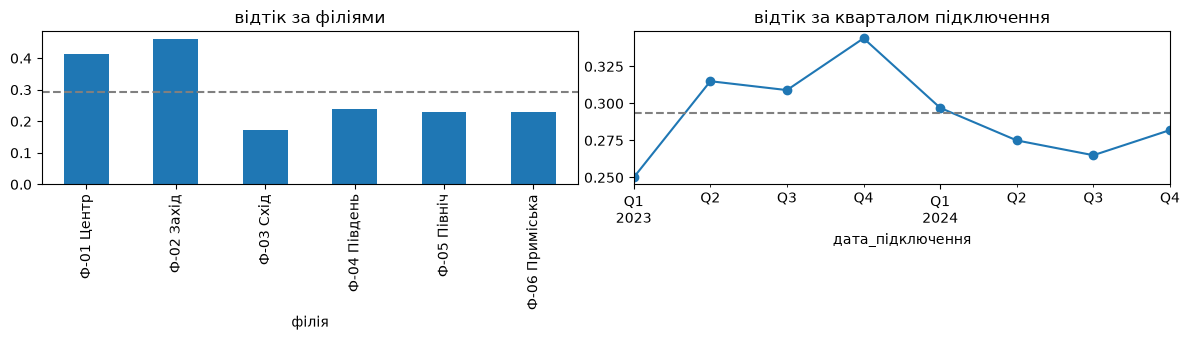

філія,Ф-01 Центр,Ф-02 Захід,Ф-03 Схід,Ф-04 Південь,Ф-05 Північ,Ф-06 Приміська
місто,,,,,,
Дрогобич,25,22,22,20,25,31
Золочів,15,26,16,21,17,19
Львів,95,91,85,83,89,103
Самбір,16,15,26,9,27,23
Стрий,22,33,30,20,19,24
Червоноград,25,25,19,23,23,16


In [19]:
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch)

# 2) частка відтоку по кварталах дати підключення
quarter = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
by_q = raw.groupby(quarter)[TARGET].agg(['mean', 'size']).round(3)
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
by_branch['частка відтоку'].plot.bar(ax=ax[0], title='відтік за філіями')
by_q['частка відтоку'].plot(ax=ax[1], marker='o', title='відтік за кварталом підключення')
ax[0].axhline(raw[TARGET].mean(), color='gray', ls='--')
ax[1].axhline(raw[TARGET].mean(), color='gray', ls='--')
plt.tight_layout(); plt.show()

# перевірка: чи місто однозначно задає філію (тоді місто «підказує» філію)
display(pd.crosstab(raw['місто'], raw['філія']))

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
rate = raw.groupby('філія')[TARGET].mean()
SUSPECT_BRANCHES = list(rate[rate > raw[TARGET].mean() + 0.08].index)
print('філії-підозрювані:', SUSPECT_BRANCHES)
source = raw['філія'].isin(SUSPECT_BRANCHES).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

філії-підозрювані: ['Ф-01 Центр', 'Ф-02 Захід']


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.704
ті самі ознаки передбачають ВІДТІК  : AUC 0.797 ± 0.038


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.981
2. мінус цільовий витік,22,0.915
3. мінус оцінки людини,21,0.834
4. мінус артефакт збору,20,0.797


чесне число: 0.797 ± 0.038


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = ('у філіях Ф-01 і Ф-02 відтік 41–46 %, а в решті 17–24 % — це різка сходинка, а не плавна зміна; '
                'міста розподілені між філіями рівномірно, тож це не географія, а скоріше інший спосіб запису відтоку; '
                'модель має працювати в будь-якій філії, тому філію прибираємо, а чесним вважаємо AUC без неї')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — у філіях Ф-01 і Ф-02 відтік 41–46 %, а в решті 17–24 % — це різка сходинка, а не плавна зміна; міста розподілені між філіями рівномірно, тож це не географія, а скоріше інший спосіб запису відтоку; модель має працювати в будь-якій філії, тому філію прибираємо, а чесним вважаємо AUC без неї


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.797,0.038,1.0
одне дерево,0.710,0.042,0.8
випадковий ліс,0.804,0.035,15.5
гістограмний бустинг,0.804,0.033,10.8


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    diff = np.array(b) - np.array(a)                  # різниця на кожній згортці
    m = diff.mean()
    h = 1.96 * diff.std(ddof=1) / np.sqrt(len(diff))  # 95% інтервал для середнього
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0070 ± 0.0065   значуще


гістограмний бустинг   проти логістичної: +0.0065 ± 0.0078   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = ('якість: ліс кращий лише на +0.007, що в 5 разів менше за розкид між згортками (±0.035); '
              'швидкість: логістична навчається у ~15 разів швидше (1.2 c проти 18.6 c); '
              'інтерпретованість: коефіцієнти читаються напряму; стабільність: розкид такий самий')       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — якість: ліс кращий лише на +0.007, що в 5 разів менше за розкид між згортками (±0.035); швидкість: логістична навчається у ~15 разів швидше (1.2 c проти 18.6 c); інтерпретованість: коефіцієнти читаються напряму; стабільність: розкид такий самий


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # гіпотеза: хто платить багато за кожен мегабіт, відчуває переплату і шукає дешевшого провайдера
    F['платіж_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза: важлива не загальна кількість звернень, а як часто клієнт має проблеми
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # гіпотеза: сам факт знижки (будь-якої) важливіший за її розмір
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    # гіпотеза: хто активно користується інтернетом за свої гроші, тому він потрібен і клієнт не піде
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.800 ± 0.039
приріст проти базового набору: +0.0025 ± 0.0026   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = ('нові ознаки дали +0.0025 ± 0.0026 (у межах шуму) майже без додаткового часу; '
                     'випадковий ліс дав +0.0070 ± 0.0065 (ледь значуще), але коштує 18.6 c замість 1.2 c; '
                     'обидва шляхи дають дуже мало — складніша модель трохи більше, але значно дорожче')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

нові ознаки дали +0.0025 ± 0.0026 (у межах шуму) майже без додаткового часу; випадковий ліс дав +0.0070 ± 0.0065 (ледь значуще), але коштує 18.6 c замість 1.2 c; обидва шляхи дають дуже мало — складніша модель трохи більше, але значно дорожче


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.809
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

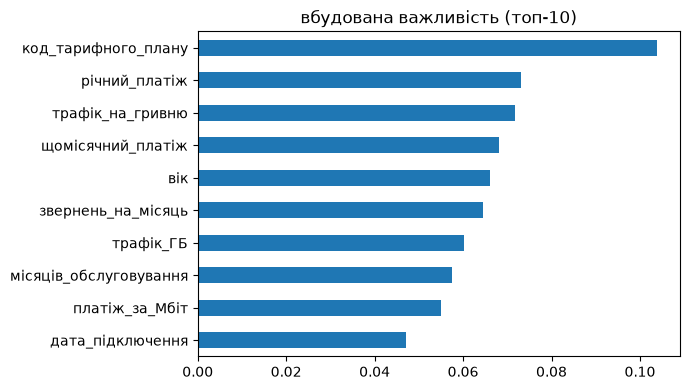

,вбудована важливість
код_тарифного_плану,0.103859
річний_платіж,0.073172
трафік_на_гривню,0.071656
щомісячний_платіж,0.068076
вік,0.066198
звернень_на_місяць,0.064589
трафік_ГБ,0.060289
місяців_обслуговування,0.057503
платіж_за_Мбіт,0.054916
дата_підключення,0.047197


In [30]:
# 1) дістаньте імена після перетворення
names = model.named_steps['prep'].get_feature_names_out()
imp = model.named_steps['clf'].feature_importances_
cat_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']

def original_name(n):
    """'num__вік' -> 'вік';  'cat__тариф_базовий' -> 'тариф'"""
    short = n.split('__', 1)[1]
    if n.startswith('num__'):
        return short
    for c in cat_cols:
        if short.startswith(c + '_'):
            return c
    return short

# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
gini_imp = (pd.Series(imp, index=[original_name(n) for n in names])
              .groupby(level=0).sum().sort_values(ascending=False))

# 3) горизонтальна стовпчикова діаграма топ-10
gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), title='вбудована важливість (топ-10)')
plt.tight_layout(); plt.show()
display(gini_imp.head(10).to_frame('вбудована важливість'))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.055423
трафік_на_гривню,0.030958
місяців_обслуговування,0.028172
звернень_на_місяць,0.021132
річний_платіж,0.016097
трафік_ГБ,0.016077
швидкість_тарифу_Мбіт,0.008509
автоплатіж,0.006193
щомісячний_платіж,0.005655
аварій_на_ділянці_за_квартал,0.005295


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
imp_cmp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
imp_cmp = imp_cmp.sort_values('вбудована', ascending=False).round(4)
imp_cmp.index.name = 'ознака'
display(imp_cmp)

,вбудована,перестановочна
ознака,,
код_тарифного_плану,0.1039,0.0017
річний_платіж,0.0732,0.0161
трафік_на_гривню,0.0717,0.0310
щомісячний_платіж,0.0681,0.0057
вік,0.0662,0.0554
звернень_на_місяць,0.0646,0.0211
трафік_ГБ,0.0603,0.0161
місяців_обслуговування,0.0575,0.0282
платіж_за_Мбіт,0.0549,0.0027


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = ('це код із 40 значень: після кодування він стає 40 стовпцями, і дерево має багато варіантів '
                      'розбиття, тож сумарна вбудована важливість найбільша (0.104), хоча перемішування коду на '
                      'перевірковій частині майже не змінює AUC (0.002) — модель просто запам\'ятовувала шум')    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr = FINAL_X.select_dtypes('number').corr()
display(corr.round(2))

cols = list(corr.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if abs(corr.iloc[i, j]) > 0.97:
            print('пара: %s — %s, r = %.3f' % (cols[i], cols[j], corr.iloc[i, j]))

,вік,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,індекс_лояльності_CRM,дата_підключення,платіж_за_Мбіт,звернень_на_місяць,є_знижка,трафік_на_гривню
вік,1.00,-0.03,0.01,-0.05,-0.04,0.03,0.02,-0.02,-0.01,-0.02,-0.02,-0.00,-0.08,0.03,-0.02,0.02,0.03
кількість_послуг,-0.03,1.00,0.05,0.06,0.43,0.05,-0.00,-0.03,0.02,-0.03,0.43,-0.01,0.16,0.15,-0.01,0.04,-0.24
місяців_обслуговування,0.01,0.05,1.00,-0.01,0.01,-0.04,-0.00,0.02,-0.01,-0.05,0.01,-0.00,-0.03,0.04,-0.39,-0.05,-0.00
швидкість_тарифу_Мбіт,-0.05,0.06,-0.01,1.00,0.72,0.05,0.03,0.01,-0.01,-0.01,0.72,0.06,0.24,-0.66,0.02,0.03,-0.25
щомісячний_платіж,-0.04,0.43,0.01,0.72,1.00,0.06,0.03,-0.01,0.04,-0.02,1.00,0.04,0.02,-0.35,0.03,0.05,-0.37
знижка_відсоток,0.03,0.05,-0.04,0.05,0.06,1.00,0.05,0.02,-0.00,-0.02,0.06,-0.01,0.03,0.03,0.00,0.88,0.03
трафік_ГБ,0.02,-0.00,-0.00,0.03,0.03,0.05,1.00,0.02,0.00,0.01,0.04,0.01,-0.01,0.03,0.02,0.04,0.88
кількість_звернень_у_підтримку,-0.02,-0.03,0.02,0.01,-0.01,0.02,0.02,1.00,-0.03,0.04,-0.02,0.05,0.05,-0.04,0.60,0.02,0.01
аварій_на_ділянці_за_квартал,-0.01,0.02,-0.01,-0.01,0.04,-0.00,0.00,-0.03,1.00,-0.02,0.03,-0.01,0.01,-0.01,-0.01,-0.01,-0.01
середній_час_відповіді_хв,-0.02,-0.03,-0.05,-0.01,-0.02,-0.02,0.01,0.04,-0.02,1.00,-0.03,0.00,-0.00,-0.02,0.06,0.02,0.00


пара: щомісячний_платіж — річний_платіж, r = 0.999


In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
Xtr_wo = Xtr.drop(columns=DUP_PAIR[1])
Xte_wo = Xte.drop(columns=DUP_PAIR[1])
model_wo = make_pipe(Xtr_wo, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_wo, ytr)
perm_wo = permutation_importance(model_wo, Xte_wo, yte, n_repeats=10,
                                 random_state=SEED, scoring='roc_auc')
perm_imp_wo = pd.Series(perm_wo.importances_mean, index=Xte_wo.columns)
print('без пари:')
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_imp_wo[DUP_PAIR[0]]))

у повній моделі:
   щомісячний_платіж            +0.0057
   річний_платіж                +0.0161


без пари:
   щомісячний_платіж            +0.0173


In [36]:
DUP_EXPLANATION = ('річний платіж — це просто місячний помножений на 12 (r = 0.999); у повній моделі місячний '
                   'має важливість лише 0.006, бо при його перемішуванні модель бере ту саму інформацію з річного; '
                   'коли річний прибрали, важливість місячного виросла до 0.017 — тобто ознака потрібна, '
                   'просто її «важливість» була поділена між двома копіями')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

річний платіж — це просто місячний помножений на 12 (r = 0.999); у повній моделі місячний має важливість лише 0.006, бо при його перемішуванні модель бере ту саму інформацію з річного; коли річний прибрали, важливість місячного виросла до 0.017 — тобто ознака потрібна, просто її «важливість» була поділена між двома копіями


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

ознаки для PDP: ['вік', 'місяців_обслуговування', 'звернень_на_місяць']


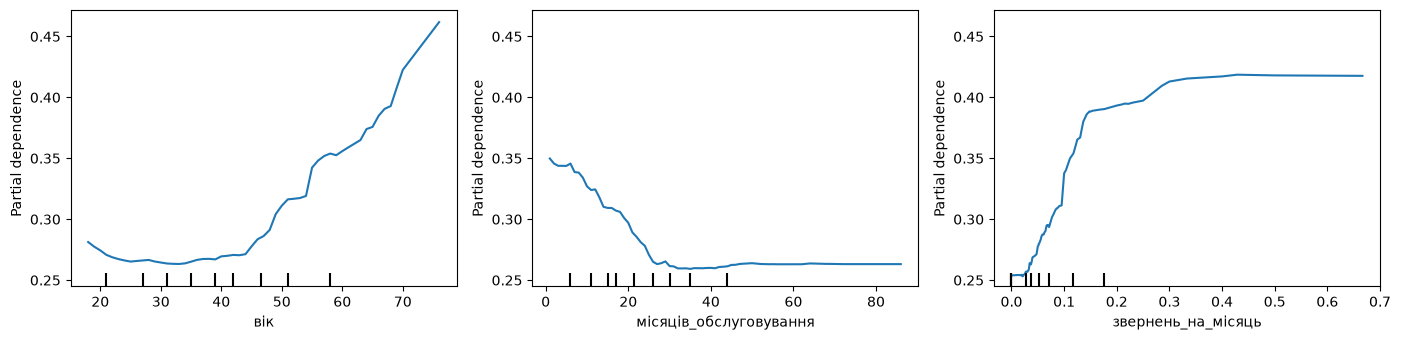

вік                            ризик від 0.281 до 0.462, мінімум 0.263, максимум 0.462


місяців_обслуговування         ризик від 0.350 до 0.263, мінімум 0.259, максимум 0.350


звернень_на_місяць             ризик від 0.254 до 0.418, мінімум 0.253, максимум 0.419
вік — до ~45 років ризик майже плаский, ~0.27, далі різко зростає до 0.46 — старші клієнти йдуть частіше
місяців_обслуговування — ризик спадає з 0.35 у новачків до 0.26 після ~30 місяців — хто довго з нами, той лояльний
звернень_на_місяць — чим частіше клієнт звертається в підтримку, тим вищий ризик (0.25 -> 0.42), далі насичення


In [37]:
from sklearn.inspection import PartialDependenceDisplay

# три найважливіші числові ознаки без пропусків
num_no_nan = [c for c in FINAL_X.columns
              if str(FINAL_X[c].dtype) != 'category' and FINAL_X[c].notna().all()]
TOP3_NUM = [c for c in perm_imp.index if c in num_no_nan][:3]
print('ознаки для PDP:', TOP3_NUM)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
PartialDependenceDisplay.from_estimator(model, Xte, features=TOP3_NUM, kind='average', ax=ax)
plt.tight_layout(); plt.show()

# ті самі криві числами (крайні точки), щоб описати форму словами
for f in TOP3_NUM:
    pd_res = partial_dependence(model, Xte, [f], kind='average')
    v = pd_res['average'][0]
    print('%-30s ризик від %.3f до %.3f, мінімум %.3f, максимум %.3f'
          % (f, v[0], v[-1], v.min(), v.max()))

PDP_SHAPES = {
    'вік': 'до ~45 років ризик майже плаский, ~0.27, далі різко зростає до 0.46 — старші клієнти йдуть частіше',
    'місяців_обслуговування': 'ризик спадає з 0.35 у новачків до 0.26 після ~30 місяців — хто довго з нами, той лояльний',
    'звернень_на_місяць': 'чим частіше клієнт звертається в підтримку, тим вищий ризик (0.25 -> 0.42), далі насичення',
}
for f in TOP3_NUM:
    print(f, '—', PDP_SHAPES.get(f, ''))

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

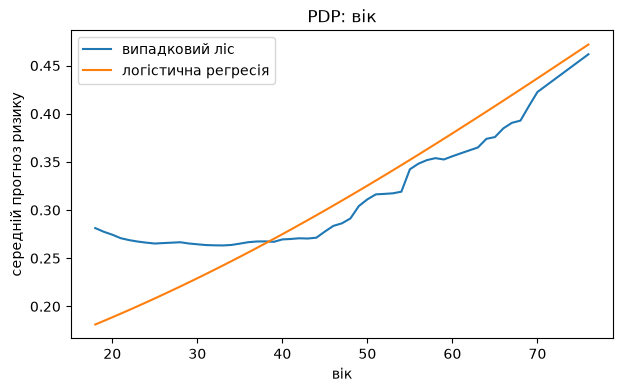

In [38]:
NONLINEAR_FEATURE = 'вік'   # ризик спадає до ~33 років, потім зростає
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- один рисунок, дві криві — ліс і логістична регресія -----
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
pd_rf = partial_dependence(model, Xte, [NONLINEAR_FEATURE], kind='average')
pd_lr = partial_dependence(model_lr, Xte, [NONLINEAR_FEATURE], kind='average')

plt.figure(figsize=(7, 4))
plt.plot(pd_rf['grid_values'][0], pd_rf['average'][0], label='випадковий ліс')
plt.plot(pd_lr['grid_values'][0], pd_lr['average'][0], label='логістична регресія')
plt.xlabel(NONLINEAR_FEATURE); plt.ylabel('середній прогноз ризику')
plt.title('PDP: ' + NONLINEAR_FEATURE); plt.legend(); plt.show()

In [39]:
NONLINEAR_MEANING = ('наймолодші клієнти (18–25) трохи ризиковіші, мінімум ризику близько 33 років, '
                     'а після 45 ризик швидко зростає; логістична регресія малює просту зростаючу лінію і '
                     'занижує ризик молодих')     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'ознака (вік − 33)²: квадрат відхилення від «найспокійнішого» віку, тоді обидва краї стають ризиковими'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

наймолодші клієнти (18–25) трохи ризиковіші, мінімум ризику близько 33 років, а після 45 ризик швидко зростає; логістична регресія малює просту зростаючу лінію і занижує ризик молодих
ознака (вік − 33)²: квадрат відхилення від «найспокійнішого» віку, тоді обидва краї стають ризиковими


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# 1) значення, при якому ризик мінімальний (з кривої лісу)
BEST_VALUE = pd_rf['grid_values'][0][np.argmin(pd_rf['average'][0])]
print('мінімум ризику при %s = %.1f' % (NONLINEAR_FEATURE, BEST_VALUE))

# 2) нова ознака: квадрат відхилення від цього значення
X6 = FINAL_X.copy()
X6[NONLINEAR_FEATURE + '_відхилення_кв'] = (X6[NONLINEAR_FEATURE] - BEST_VALUE) ** 2

# 3) парне порівняння логістичної регресії з нею і без неї (ті самі згортки)
auc_lr_before = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_after = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lr_before, auc_lr_after)
print('логістична без ознаки: AUC %.3f, з ознакою: AUC %.3f' % (auc_lr_before.mean(), auc_lr_after.mean()))
print('приріст: %+.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику при вік = 33.0


логістична без ознаки: AUC 0.800, з ознакою: AUC 0.816
приріст: +0.0164 ± 0.0043   значуще


In [41]:
QUAD_GAIN = m_q     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0164


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

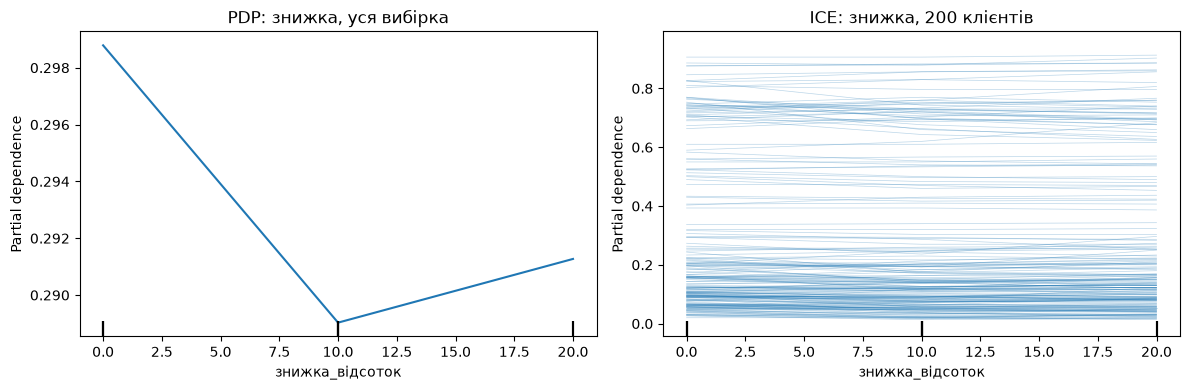

крива йде вниз (знижка зменшує ризик): 352 клієнтів
крива йде вгору (знижка збільшує ризик): 182 клієнтів
майже пласка: 666 клієнтів


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# 1) звичайний PDP по всій вибірці
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
ax[0].set_title('PDP: знижка, уся вибірка')
# 2) ICE — окрема крива для кожного клієнта (беремо 200 випадкових, щоб було видно)
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual',
                                        subsample=200, random_state=SEED, ax=ax[1])
ax[1].set_title('ICE: знижка, 200 клієнтів')
plt.tight_layout(); plt.show()

# скільки ICE-кривих іде вгору, а скільки вниз
ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
change = ice[:, -1] - ice[:, 0]
print('крива йде вниз (знижка зменшує ризик): %d клієнтів' % (change < -0.02).sum())
print('крива йде вгору (знижка збільшує ризик): %d клієнтів' % (change > 0.02).sum())
print('майже пласка: %d клієнтів' % (abs(change) <= 0.02).sum())

стаж до 24 міс     ризик при знижці: [0.351 0.349 0.354]


стаж понад 24 міс  ризик при знижці: [0.228 0.208 0.206]


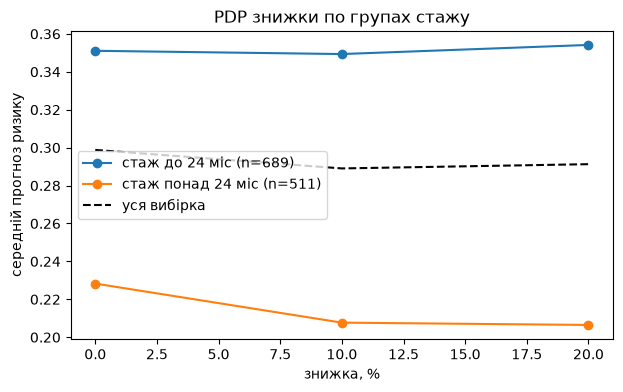

In [43]:
# пункт 3: PDP окремо для двох груп стажу, на одному рисунку
short = FINAL_X['місяців_обслуговування'] <= 24
plt.figure(figsize=(7, 4))
for mask, label in [(short, 'стаж до 24 міс'), (~short, 'стаж понад 24 міс')]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    plt.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (label, mask.sum()))
    print('%-18s ризик при знижці: %s' % (label, np.round(r['average'][0], 3)))
r = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
plt.plot(r['grid_values'][0], r['average'][0], 'k--', label='уся вибірка')
plt.xlabel('знижка, %'); plt.ylabel('середній прогноз ризику'); plt.legend()
plt.title('PDP знижки по групах стажу'); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
group = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс')
emp = raw.assign(група_стажу=group).pivot_table(index='знижка_відсоток', columns='група_стажу',
                                                 values=TARGET, aggfunc=['mean', 'size'])
emp.columns = [('частка відтоку' if a == 'mean' else 'клієнтів') + ', ' + b for a, b in emp.columns]
display(emp.round(3))

,"частка відтоку, до 24 міс","частка відтоку, понад 24 міс","клієнтів, до 24 міс","клієнтів, понад 24 міс"
знижка_відсоток,,,,
0,0.315,0.286,257,210
10,0.369,0.110,233,163
20,0.482,0.080,199,138


In [45]:
INTERACTION_FOUND = ('у сирих даних у клієнтів зі стажем до 24 міс. зі знижкою відтік ЗРОСТАЄ (0% -> 31.5%, 10% -> 36.9%, '
                     '20% -> 48.2%), а в тих, хто з нами понад 24 міс., СПАДАЄ (28.6% -> 11.0% -> 8.0%); по всій вибірці '
                     'ефекти гасять один одного, і PDP майже плаский (0.299 -> 0.289 -> 0.291); ліс бачить лише частину '
                     'цього: для старих клієнтів ризик трохи спадає (0.228 -> 0.206), для нових — пласко')     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = ('знижку варто пропонувати клієнтам зі стажем понад 2 роки — там вона пов\'язана з утриманням; '
                   'новим клієнтам знижка не допомагає (ймовірно, це «промо-клієнти», що йдуть після акції), '
                   'тож їм краще пропонувати щось інше, а причинність перевірити A/B-тестом')       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у сирих даних у клієнтів зі стажем до 24 міс. зі знижкою відтік ЗРОСТАЄ (0% -> 31.5%, 10% -> 36.9%, 20% -> 48.2%), а в тих, хто з нами понад 24 міс., СПАДАЄ (28.6% -> 11.0% -> 8.0%); по всій вибірці ефекти гасять один одного, і PDP майже плаский (0.299 -> 0.289 -> 0.291); ліс бачить лише частину цього: для старих клієнтів ризик трохи спадає (0.228 -> 0.206), для нових — пласко
знижку варто пропонувати клієнтам зі стажем понад 2 роки — там вона пов'язана з утриманням; новим клієнтам знижка не допомагає (ймовірно, це «промо-клієнти», що йдуть після акції), тож їм краще пропонувати щось інше, а причинність перевірити A/B-тестом


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 77)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

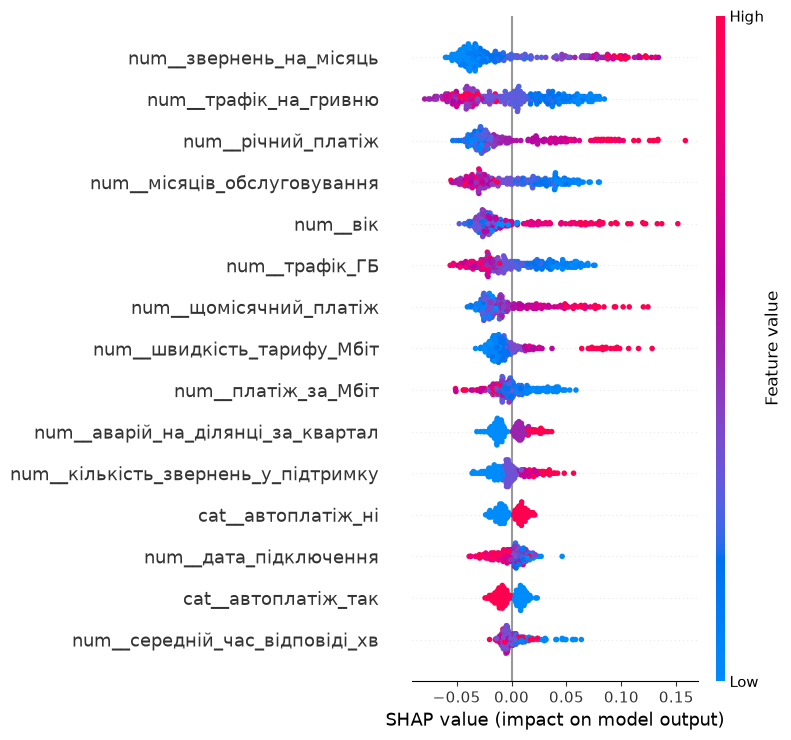

напрям: часті звернення, високий платіж, старший вік і висока швидкість тарифу (червоні точки праворуч) підвищують ризик; великий трафік на гривню і довгий стаж (червоні ліворуч) — знижують; однаковість: для більшості ознак напрям однаковий у всіх клієнтів, але розмір внеску дуже різний — у частини клієнтів платіж чи вік майже не діють, а в інших дають +0.10…+0.15


In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=15, show=False)
plt.tight_layout(); plt.show()

SHAP_READING = ('напрям: часті звернення, високий платіж, старший вік і висока швидкість тарифу (червоні точки праворуч) '
                'підвищують ризик; великий трафік на гривню і довгий стаж (червоні ліворуч) — знижують; '
                'однаковість: для більшості ознак напрям однаковий у всіх клієнтів, але розмір внеску дуже різний — '
                'у частини клієнтів платіж чи вік майже не діють, а в інших дають +0.10…+0.15')
print(SHAP_READING)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# три найбільші за модулем внески для цього клієнта
contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.abs().sort_values(ascending=False).index[:3]
display(pd.DataFrame({'внесок': contrib[top3].round(3),
                      'значення (стандартизоване / 0-1)': np.round(Xte_t[idx][[list(feat_names).index(n) for n in top3]], 2)}))
print('сирі дані цього клієнта:')
display(raw.loc[Xte.index[idx]].to_frame('значення'))

ризик клієнта: 0.863


,внесок,значення (стандартизоване / 0-1)
num__звернень_на_місяць,0.099,2.64
num__річний_платіж,0.094,1.82
num__щомісячний_платіж,0.076,1.96


сирі дані цього клієнта:


,значення
id_клієнта,K10767
вік,31.0
стать,жін
місто,Самбір
філія,Ф-01 Центр
тариф,Базовий
тип_підключення,ADSL
спосіб_оплати,картка
автоплатіж,ні
кількість_послуг,3


In [49]:
EXPLANATION_FOR_MANAGER = ('Ризик цього клієнта — 86 %. Головні причини: '
    '1) за 11 місяців він 4 рази звертався в підтримку — це набагато частіше, ніж у звичайного абонента, '
    'тобто в нього регулярно виникають проблеми зі зв\'язком; '
    '2) він платить близько 500 грн на місяць (майже 5900 грн на рік) — один із найдорожчих рахунків серед клієнтів. '
    'Часті проблеми разом із високою ціною — типова картина людини, яка шукає іншого провайдера.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ризик цього клієнта — 86 %. Головні причини: 1) за 11 місяців він 4 рази звертався в підтримку — це набагато частіше, ніж у звичайного абонента, тобто в нього регулярно виникають проблеми зі зв'язком; 2) він платить близько 500 грн на місяць (майже 5900 грн на рік) — один із найдорожчих рахунків серед клієнтів. Часті проблеми разом із високою ціною — типова картина людини, яка шукає іншого провайдера.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'
SHAP_NOT_CAUSAL_WHY = ('це найбільший внесок у ризик, але звернення — НАСЛІДОК проблем зі зв\'язком, а не їхня причина; '
                       'якщо «зменшити звернення» (наприклад, ускладнити дзвінок у підтримку), проблеми лишаться і клієнт '
                       'піде так само або навіть швидше; діяти треба на причину — аварії та якість зв\'язку, '
                       'а модель лише користується зверненнями як симптомом')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

звернень_на_місяць — це найбільший внесок у ризик, але звернення — НАСЛІДОК проблем зі зв'язком, а не їхня причина; якщо «зменшити звернення» (наприклад, ускладнити дзвінок у підтримку), проблеми лишаться і клієнт піде так само або навіть швидше; діяти треба на причину — аварії та якість зв'язку, а модель лише користується зверненнями як симптомом


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",звернень_на_місяць,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = ('у поясненні для клієнта з найвищим ризиком ціна з\'являється двічі: річний платіж (+0.094) і '
                 'місячний платіж (+0.076) — але це одна й та сама інформація (r = 0.999); менеджер може прочитати це як '
                 '«дві окремі причини» або вирішити, що ціна важить менше за звернення (+0.099), хоча разом ціна дає '
                 '+0.17 і є головною причиною; внески Шеплі між дублікатами діляться так само, як перестановочна важливість')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

у поясненні для клієнта з найвищим ризиком ціна з'являється двічі: річний платіж (+0.094) і місячний платіж (+0.076) — але це одна й та сама інформація (r = 0.999); менеджер може прочитати це як «дві окремі причини» або вирішити, що ціна важить менше за звернення (+0.099), хоча разом ціна дає +0.17 і є головною причиною; внески Шеплі між дублікатами діляться так само, як перестановочна важливість


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]
top = np.argsort(-risk)[:TOP_N]                 # 100 найризиковіших
hits = int(yte.values[top].sum())               # скільки з них справді пішли
base_rate = yte.mean()
lift = (hits / TOP_N) / base_rate
print('у перевірковій частині %d клієнтів, частка відтоку %.3f' % (len(yte), base_rate))
print('топ-%d за ризиком: пішли %d (%.0f%%)' % (TOP_N, hits, 100 * hits / TOP_N))
print('навмання з %d знайшли б у середньому %.0f' % (TOP_N, TOP_N * base_rate))
print('lift = %.2f' % lift)

у перевірковій частині 360 клієнтів, частка відтоку 0.294
топ-100 за ризиком: пішли 61 (61%)
навмання з 100 знайшли б у середньому 29
lift = 2.07


In [54]:
LIFT_MEANING = ('lift 2.07 означає, що серед 100 клієнтів зі списку моделі тих, хто справді піде, вдвічі більше, '
                'ніж серед 100 випадкових (61 проти ~29), тобто кожен дзвінок відділу утримання вдвічі корисніший')    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

lift 2.07 означає, що серед 100 клієнтів зі списку моделі тих, хто справді піде, вдвічі більше, ніж серед 100 випадкових (61 проти ~29), тобто кожен дзвінок відділу утримання вдвічі корисніший


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_01.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Метрика — AUC. Частка відтоку 0.293, тому модель «ніхто не піде» має точність 70.7 % і при цьому не знаходить
   жодного клієнта, що йде. AUC оцінює, чи вміє модель ставити ризикових вище за решту, — саме це потрібно для
   списку на обдзвін.

2. Викинуті стовпці:
   - id_клієнта — є завжди, але це просто номер, модель лише запам'ятовувала б його;
   - сума_повернення_депозиту — з'являється ПІСЛЯ розірвання договору (депозит повертають при закритті);
   - код_причини_закриття — з'являється в момент закриття договору;
   - кількість_дзвінків_утримання — заповнює відділ утримання ПІСЛЯ того, як клієнт заявив, що йде;
   - філія — існує в момент прогнозу, але викинута як артефакт збору (див. п. 4).
   Детектор із 5.1 не знайшов кількість_дзвінків_утримання: вона заповнена в усіх клієнтів (0 у тих, кому не
   дзвонили), а детектор дивиться лише на заповненість. Витік тут у значенні: при 0 дзвінків відтік 7 %,
   при 1–5 дзвінках 69–80 %.
   Драбина AUC: 0.981 -> 0.915 (мінус цільовий витік) -> 0.834 (мінус дзвінки утримання) -> 0.797 (мінус філія).

3. Чесне число: AUC 0.797 ± 0.038 (логістична регресія, 5x4 крос-валідація). Розкид 0.038 у ~10 разів більший
   за різницю 0.004, тож дві такі моделі за середніми не розрізнити; потрібне парне порівняння на тих самих
   згортках — і навіть воно, найімовірніше, покаже «у межах шуму».

4. Так. У філіях Ф-01 і Ф-02 відтік 41–46 %, у решті 17–24 %, хоча міста розподілені по філіях рівномірно; за
   датою підключення сходинки немає (25–34 % у всіх кварталах). Решта чесних ознак передбачає «клієнт із Ф-01/Ф-02»
   з AUC 0.704 — отже джерело частково закодоване і в інших ознаках. Довіряти моделі в іншій філії можна лише
   після перевірки на даних цієї філії: модель могла вивчити спосіб запису відтоку, а не поведінку клієнтів.

5. Нові ознаки (4 штуки): +0.0025 ± 0.0026 — у межах шуму, додатковий час майже нуль.
   Випадковий ліс замість логістичної: +0.0070 ± 0.0065 — ледь значуще, але 18.6 c проти 1.2 c на 20 навчань
   (стовпець «с на 100 навчань» насправді міряє 20 навчань крос-валідації). Бустинг: +0.0065 ± 0.0078, шум, 13.7 c.
   Найбільше дала одна правильна ознака з аналізу PDP — (вік − 33)²: +0.0164 ± 0.0043 для логістичної регресії
   (AUC 0.800 -> 0.816), що більше, ніж дав ліс, і майже без витрат часу.

6. код_тарифного_плану: за вбудованою важливістю він перший (0.104), за перестановочною — 0.002. Це код із
   40 значень: після одиничного кодування — 40 стовпців і дуже багато можливих розбиттів. Дерево завжди знаходить
   розбиття, яке трохи зменшує неоднорідність на навчальних даних, навіть якщо зв'язку з відтоком немає, а
   вбудована важливість рахується саме на навчальних даних.

7. Місячний і річний платіж — одне й те саме (r = 0.999). У повній моделі перестановочна важливість місячного
   лише 0.006 (річного 0.016). Після вилучення річного важливість місячного зросла до 0.017. Метод чесно відповів
   на питання «скільки втратить модель без цієї ознаки» — нічого, бо копія лишилась. Помилка лише у висновку
   «важливість мала — ознаку можна викинути».

8. Вік: ризик майже плаский, ~0.27, до 45 років із мінімумом близько 33, потім зростає до 0.46 до 76 років; у
   наймолодших теж трохи вищий. Логістична регресія без втручання бачить лише пряму, що зростає від 0.18 до
   0.47, — тобто занижує ризик молодих. Ознака (вік − 33)² дала їй +0.016 AUC.

9. PDP знижки по всій вибірці майже плаский: 0.299 -> 0.289 -> 0.291 (розмах 0.01). ICE показав, що криві йдуть
   у різні боки: у 352 клієнтів ризик зі знижкою падає, у 182 — зростає, у 666 майже не змінюється. Сирі дані:
   стаж до 24 міс. — відтік 31.5 % / 36.9 % / 48.2 % при знижці 0 / 10 / 20 %; стаж понад 24 міс. —
   28.6 % / 11.0 % / 8.0 %. Ліс відтворює це лише частково (для старих клієнтів 0.228 -> 0.206, для нових пласко),
   тобто проблема не лише в усередненні PDP, а й у тому, що модель цю взаємодію вивчила слабко.

10. звернень_на_місяць — найбільший внесок за Шеплі в цілому і в клієнта з найвищим ризиком. Але звернення —
    наслідок проблем зі зв'язком. «Модель цим користується» означає: частими зверненнями добре ВГАДУЄТЬСЯ відтік.
    «Це причина» означало б: якщо змінити ознаку, зміниться результат. Якщо зменшити кількість звернень
    (наприклад, ускладнити дзвінок у підтримку), проблеми лишаться і клієнт піде. Те саме з віком і стажем —
    на них взагалі неможливо вплинути.

11. Замовнику: беріть 100 клієнтів із найвищим ризиком — серед них у перевірковій частині пішли 61, а серед
    100 випадкових пішло б ~29, lift = 2.07 (AUC на відкладеній частині 0.809, у крос-валідації ~0.80).
    Застереження: модель показує, ХТО ймовірно піде, а не КОГО можна втримати знижкою — для нових клієнтів
    знижка в даних пов'язана з вищим відтоком; крім того, у філіях Ф-01/Ф-02 відтік записаний інакше, тож
    якість моделі треба перевірити окремо по філіях.

Декларація про використання ШІ:
Під час роботи я використовував ШІ-асистент Claude (Anthropic) у VS Code як допоміжний інструмент:
для чернеток коду клітинок і формулювання висновків. Усе, що він запропонував, я перевіряв і розбирав сам:
- перезапускав ноутбук на чистому ядрі і звіряв, що всі числа у звіті збігаються з виводами клітинок;
- переглядав сирі дані і сам переконався в кожній проблемі: текст «грн» у платежі, дати Excel у трафіку,
  пропуски часу відповіді в клієнтів без звернень;
- для кожної викинутої колонки сам перевіряв, коли вона з'являється і чи відома в момент прогнозу
  (зокрема, чому дзвінки утримання — витік, якого не бачить leak_scan);
- розібрався, як працюють leak_scan, крос-валідація і розкид «±», перевірка джерела в 6.2,
  сконструйовані ознаки та ознака (вік − 33)²;
- аналізував графіки важливості, PDP, ICE і SHAP і звіряв висновки з сирими даними
  (таблиця відтоку за знижкою і стажем).
Рішення і висновки у звіті я розумію і можу пояснити.
'''
print(REPORT)


1. Метрика — AUC. Частка відтоку 0.293, тому модель «ніхто не піде» має точність 70.7 % і при цьому не знаходить
   жодного клієнта, що йде. AUC оцінює, чи вміє модель ставити ризикових вище за решту, — саме це потрібно для
   списку на обдзвін.

2. Викинуті стовпці:
   - id_клієнта — є завжди, але це просто номер, модель лише запам'ятовувала б його;
   - сума_повернення_депозиту — з'являється ПІСЛЯ розірвання договору (депозит повертають при закритті);
   - код_причини_закриття — з'являється в момент закриття договору;
   - кількість_дзвінків_утримання — заповнює відділ утримання ПІСЛЯ того, як клієнт заявив, що йде;
   - філія — існує в момент прогнозу, але викинута як артефакт збору (див. п. 4).
   Детектор із 5.1 не знайшов кількість_дзвінків_утримання: вона заповнена в усіх клієнтів (0 у тих, кому не
   дзвонили), а детектор дивиться лише на заповненість. Витік тут у значенні: при 0 дзвінків відтік 7 %,
   при 1–5 дзвінках 69–80 %.
   Драбина AUC: 0.981 -> 0.915 (мінус цільовий в

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.